# 00d · EDA on both datasets

**Purpose.** Plot example sensor curves per class and class counts (per class, session and day) for both datasets.

**Inputs**
- GasWindTunnel `X_signals.npy` (600, 72, 1500) + `meta.csv`
- EverydayScents `X_signals.npy` (144, 11, 210) + `meta.csv`

**Outputs**
- Figures in `report/figures/` (example curves, class counts)

In [1]:
import sys
sys.path.append("../..")          # project root, so that `import src` works

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
from src.cv import load_processed, make_folds, SEEDS

FIG = ROOT / "report/figures"
FIG.mkdir(parents=True, exist_ok=True)

data = {d: load_processed(d) for d in ["gwt", "es"]}     # X (N, C, T), meta, info
for d, (X, meta, info) in data.items():
    print(d, X.shape, "baseline points:", info["n_base"])

gwt (600, 72, 1500) baseline points: 150
es (144, 11, 210) baseline points: 60


## Class counts

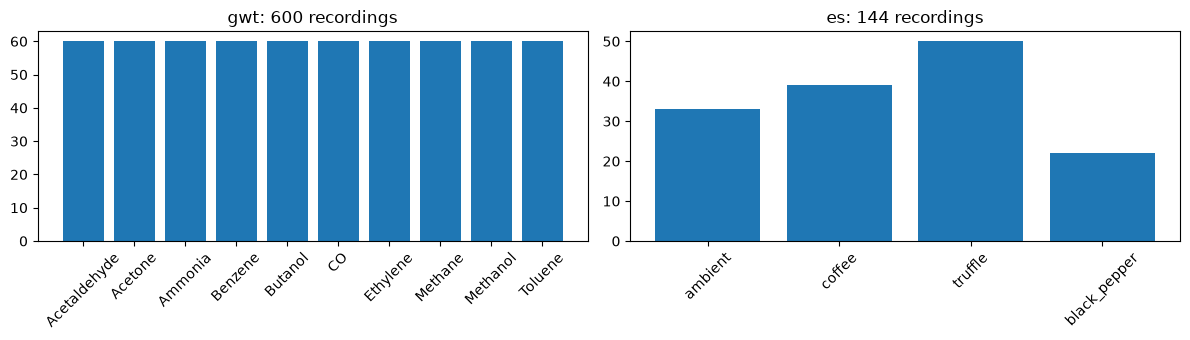

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (d, (X, meta, info)) in zip(axes, data.items()):
    counts = meta["y_multi"].value_counts().sort_index()
    ax.bar([info["classes"][k] for k in counts.index], counts.values)
    ax.set_title(f"{d}: {len(meta)} recordings")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG / "00d_class_counts.png", dpi=150)
plt.show()

## Example curves: mean response per class
GasWindTunnel: the sensor with the largest response; EverydayScents: four channels.

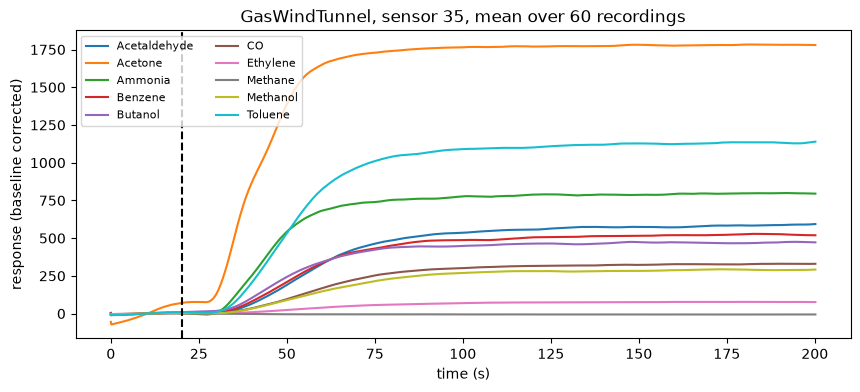

In [3]:
X, meta, info = data["gwt"]
s = np.abs(X).mean(axis=(0, 2)).argmax()                      # most responsive sensor
t = np.array(info["time_s"])                                 # (1500,) nominal seconds
fig, ax = plt.subplots(figsize=(10, 4))
for k, gas in enumerate(info["classes"]):
    ax.plot(t, X[meta["y_multi"] == k, s].mean(axis=0), label=gas)  # (1500,)
ax.axvline(t[info["n_base"]], color="k", ls="--")        # gas release
ax.set(xlabel="time (s)", ylabel="response (baseline corrected)", title=f"GasWindTunnel, sensor {s}, mean over 60 recordings")
ax.legend(ncol=2, fontsize=8)
plt.savefig(FIG / "00d_gwt_mean_curves.png", dpi=150)
plt.show()

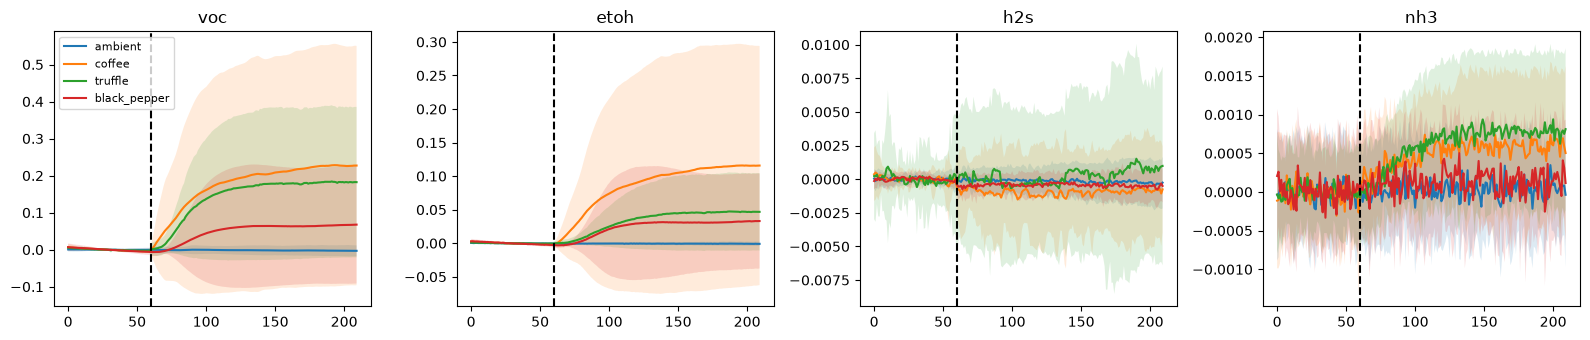

In [4]:
X, meta, info = data["es"]
show = ["voc", "etoh", "h2s", "nh3"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, ch in zip(axes, show):
    c = info["channels"].index(ch)
    for k, name in enumerate(info["classes"]):
        curves = X[meta["y_multi"] == k, c]                      # (n_class, 210)
        m, sd = curves.mean(axis=0), curves.std(axis=0)
        ax.plot(m, label=name)
        ax.fill_between(np.arange(len(m)), m - sd, m + sd, alpha=0.15)
    ax.axvline(info["n_base"], color="k", ls="--")
    ax.set_title(ch)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "00d_es_mean_curves.png", dpi=150)
plt.show()

## Test-fold class counts of the planned CV splits
Risk check from the plan: with only 8 black_pepper sessions, a grouped fold may get very few (or no) black_pepper samples.

In [5]:
for d in ["gwt", "es"]:
    X, meta, info = data[d]
    rows = []
    for seed in SEEDS:
        for fold, (tr, te) in enumerate(make_folds(d, meta, seed)):
            c = meta["y_multi"].iloc[te].value_counts().reindex(range(len(info["classes"])), fill_value=0)
            rows.append({"seed": seed, "fold": fold, "n_train": len(tr), "n_test": len(te),
                         **dict(zip(info["classes"], c.values))})
    table = pd.DataFrame(rows)
    print(d)
    display(table)
    if d == "es":
        _, groups = meta["y_multi"], meta["session_id"]
        leaks = [len(set(groups.iloc[tr]) & set(groups.iloc[te]))
                 for seed in SEEDS for tr, te in make_folds(d, meta, seed)]
        print("sessions shared between train and test in any fold:", sum(leaks))

gwt


,seed,fold,n_train,n_test,Acetaldehyde,Acetone,Ammonia,Benzene,Butanol,CO,Ethylene,Methane,Methanol,Toluene
0,0,0,480,120,12,12,12,12,12,12,12,12,12,12
1,0,1,480,120,12,12,12,12,12,12,12,12,12,12
2,0,2,480,120,12,12,12,12,12,12,12,12,12,12
3,0,3,480,120,12,12,12,12,12,12,12,12,12,12
4,0,4,480,120,12,12,12,12,12,12,12,12,12,12
5,1,0,480,120,12,12,12,12,12,12,12,12,12,12
6,1,1,480,120,12,12,12,12,12,12,12,12,12,12
7,1,2,480,120,12,12,12,12,12,12,12,12,12,12
8,1,3,480,120,12,12,12,12,12,12,12,12,12,12
9,1,4,480,120,12,12,12,12,12,12,12,12,12,12


es


,seed,fold,n_train,n_test,ambient,coffee,truffle,black_pepper
0,0,0,116,28,7,8,10,3
1,0,1,115,29,8,8,10,3
2,0,2,116,28,6,8,10,4
3,0,3,115,29,6,7,10,6
4,0,4,114,30,6,8,10,6
5,1,0,116,28,6,8,10,4
6,1,1,114,30,6,8,10,6
7,1,2,115,29,8,8,10,3
8,1,3,115,29,6,7,10,6
9,1,4,116,28,7,8,10,3


sessions shared between train and test in any fold: 0
